In [5]:
import jax
import os

# Avoid OOM errors
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]=".49"
# os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"
print(f"JAX backend: {jax.default_backend()}")

JAX backend: gpu


If you don't set the GPU memory allocation, then you can accidentally run out of memory. Sometimes GPU usage is persistant because notebooks, I think.

In [6]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [8]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Pulses

We now have a pair of identity gates.

Adjusting X1 to amplitude 0.20078359553005384
Adjusting X2 to amplitude 0.2029490387398391
Adjusting SX1 to amplitude 0.20052729286337825
Adjusting SX2 to amplitude 0.20248564954832834
Adjusting I1 to amplitude 0.2016346225391911


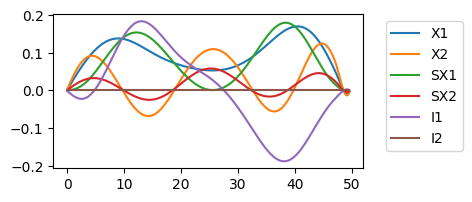

In [9]:
# Load shapes
fname = "../pico-pulses/saved-pulses-2024-02-16/a_single_qubit_gateset_R1e-5.csv"
knames = ["X1", "X2", "SX1", "SX2", "I1"]
pico_a = {k: v for k, v in zip(knames, ps.from_csv(fname))}
# pico_a["I2"] = np.zeros(pico_a["I1"].shape)

# The initial run takes awhile to construct the symbolic pulse shapes
x_gates = {}
for k, v in pico_a.items():
    x_gates[k] = ps.scalable_symbolic_pulse(duration_1qb, v, f"custom-{k}")

# Calibrate the robust X gates
ts = np.arange(0, dt * duration_1qb, dt)
fig, ax = plt.subplots(1, 1, figsize=[4,2])
cal_x_gates = {}
# Only hit the first 4 gates
cal_values = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi]
cal_amps = []
for θ, (k, v) in zip(cal_values, x_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_amps.append(amp)
    print(f"Adjusting {k} to amplitude {amp}")
    cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
    )
    ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

k = "I1"
v = x_gates[k]
amp = np.median(cal_amps)
print(f"Adjusting {k} to amplitude {amp}")
cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
)
ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

k = "I2"
v = ps.zero_envelope(duration_1qb)
cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=0.0,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
)
ax.plot(ts, ps.get_samples(cal_x_gates[k]).real, label=k)

# Add legend
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Calibrate the default X gates
default_gates = {}
for k in pico_a.keys():
    if "SX" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 4)
    elif "X" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 2)
    elif "I" in k:
        default_gates[k] = ps.zero_envelope(duration_1qb)
    else:
        raise ValueError(f"Unknown gate {k}")
default_gates["I2"] = ps.zero_envelope(duration_1qb)


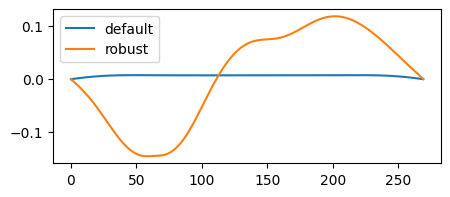

In [10]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"
knames = ["default", "robust"]
pico2_a = {k: ps.from_csv(fname(k))[0] for k in knames}

# Less precise about optimization than before...
fig, ax = plt.subplots(figsize=[5, 2])
for k, v in pico2_a.items():
    ax.plot(v, label=k)
ax.legend()

# Downsample the pulse to make construction faster
cr_gates = {}
for k, v in pico2_a.items():
    cr_gates[k] = ps.scalable_symbolic_pulse(
        duration_2qb,
        ps.resample(51, v, keep_step=False),
        f"cr-{k}"
    )

# Add positive and negative rotations to gateset
cal_cr_gates = {}
cal_values = [0.125 * np.pi, 0.125 * np.pi]
for θ, (k, v) in zip(cal_values, cr_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_cr_gates[k] = {
        "+": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated+amp",
            duration=duration_2qb,
            amp=amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
        "-": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated-amp",
            duration=duration_2qb,
            amp=-amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
    }

# Circuits

In [11]:
# Set the parameters globally for the model
N = 4  # number of spins
hz = 1.0 * 2 * np.pi  # magnetic field along z
Jx = 1.0 * 2 * np.pi  # Coupling along x
Δt = 0.05  # time step for integration


def create_initial_state(qr, cr):
    '''
    Creates the initial state for the experiment.
    Here we would like to prepare the |+>|+>|+>|+> state.
    '''
    circ = qk.QuantumCircuit(qr, cr)
    [circ.h(qr[i]) for i in range(qr.size)]
    return circ


def rxx(circ, θx, q1, q2):
    '''
    Implements the exp(-i theta/2 sx_1 sx_2) gate.
    '''
    circ.cx(q1, q2)
    circ.rx(θx, q1)
    circ.cx(q1, q2)
    return circ


def first_order_Trotter_unitary(circ, Δt, barrier=False):
    '''
    Applies a Unitary for a single time step U(Δt) using first-order trotter expansion to the input quantum circuit.
    input : circ is a quantum circuit
    output : circ-U(Δt)-
    '''
    # Layer A: coupling XX between n and n+1
    # Induce parallel CR gates
    if barrier:
        circ.barrier()
    for p in range(0, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])
    if barrier:
        circ.barrier()
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])

    #  Alt., a naive loop will apply XX rotations sequentially, failing to stack.
    # for p in range(0, circ.num_qubits - 1):
    #     circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])

    # Layer B: on-site Z
    for p in range(circ.num_qubits):    
        circ.rz(hz*Δt, circ.qubits[p])

    return circ


def second_order_Trotter_unitary(circ, Δt, barrier=False):
    '''
    Applies a Unitary for a single time step U(Δt) using second-order trotter expansion to the input quantum circuit.
    input : circ is a quantum circuit
    output : circ-U(Δt)-
    '''
    # Layer 2: on-site Z (half)
    for p in range(circ.num_qubits):
        circ.rz(hz * Δt / 2, circ.qubits[p])
 
    # Layer 1: coupling XX between n and n+1
    # Induce parallel structure (and symmetry)
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt / 2, circ.qubits[p], circ.qubits[p+1])
    # NOTE: Add barriers to separate the parallel section
    if barrier:
        circ.barrier()
    for p in range(0, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p+1])
    if barrier:
        circ.barrier()
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt / 2, circ.qubits[p], circ.qubits[p+1])

    # Layer 2: on-site Z (half)
    for p in range(circ.num_qubits):
        circ.rz(hz * Δt / 2, circ.qubits[p])
    return circ

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit/quantum_info/operators/measures.py:399: UserWarning: Treating array input as a SuperOp object
  warnings.warn(f"Treating array input as a {fallback_class.__name__} object")
/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit/quantum_info/operators/measures.py:399: UserWarning: Treating array input as a Operator object
  warnings.warn(f"Treating array input as a {fallback_class.__name__} object")


Fidelity:  1.0000000000000022


/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


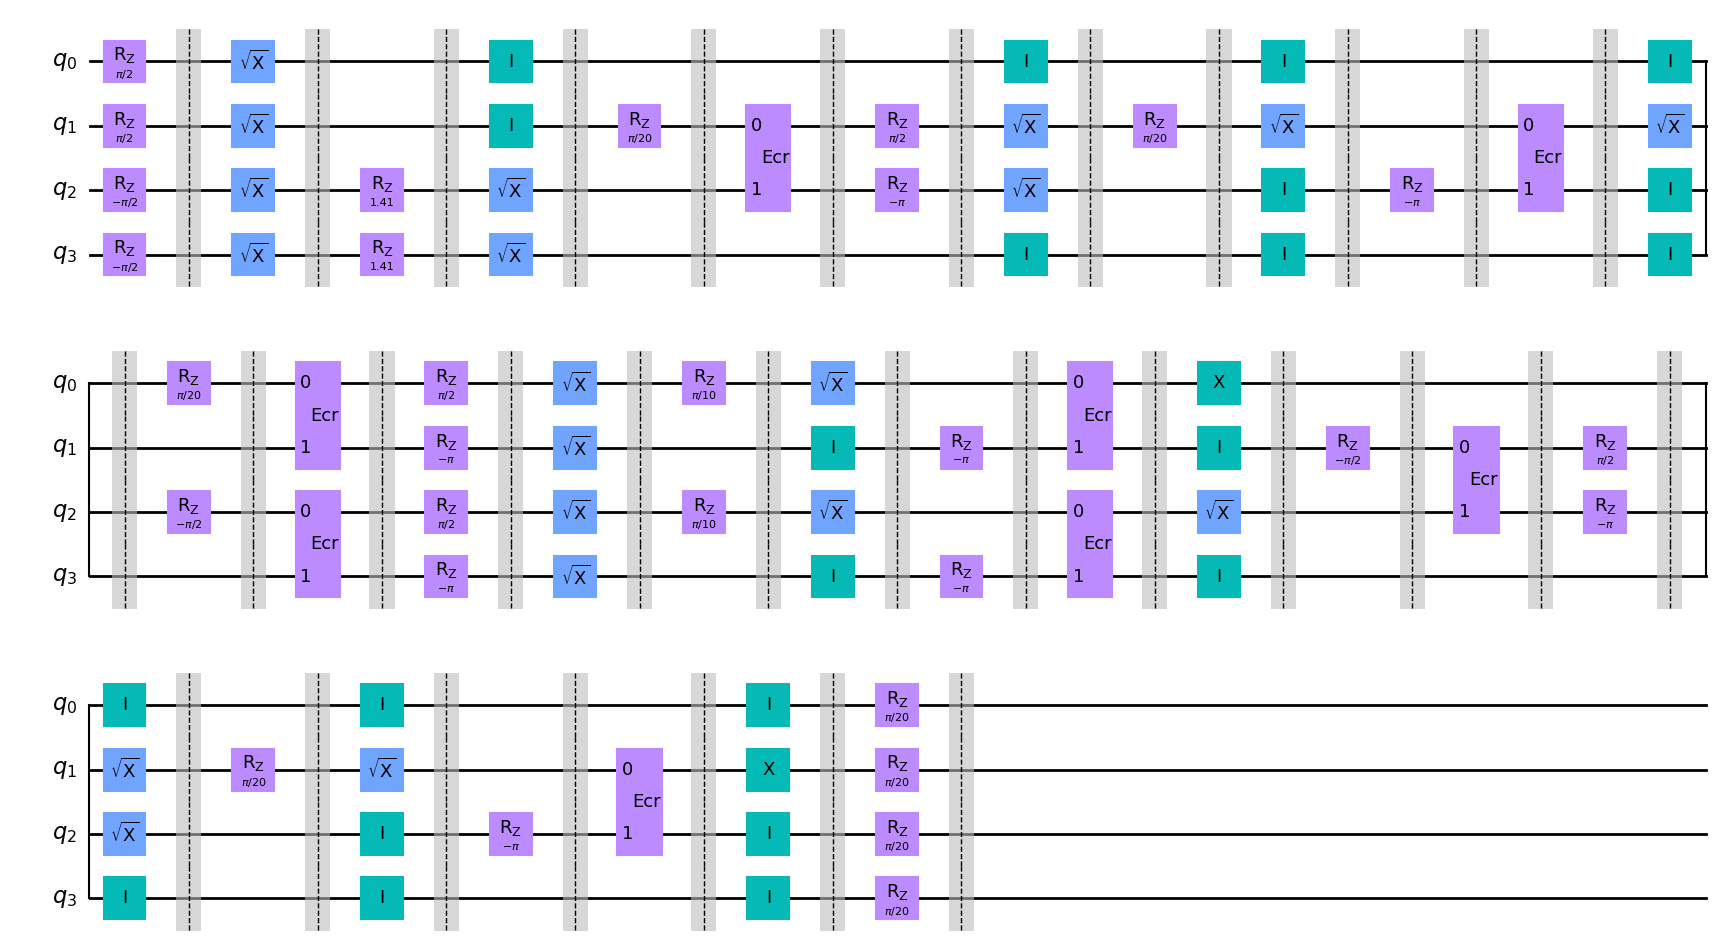

In [12]:
"""
Test the circuit with identity gates inserted
"""


registers = [0, 1, 2, 3]

qr = qk.QuantumRegister(len(registers))
cr = qk.ClassicalRegister(len(registers))
circ = create_initial_state(qr, cr)
circ = second_order_Trotter_unitary(circ, Δt)

mb = ps.MomentBuilder()
my_moments = mb.build_moments(circ)
my_moments_prev = np.copy(my_moments)

# Add in explicit identity gates
for m in my_moments:
    if ps.get_moment_case(m) == "single":
        missing = [i for i in range(len(registers)) if i not in m.keys()]
        for k in missing:
            m[k] = "I1" if k % 2 == 0 else "I2"

circ1 = ps.build_circuit(my_moments_prev, registers, barriers=True)
circ2 = ps.build_circuit(my_moments, registers, barriers=True)
print("Fidelity: ", qk.quantum_info.process_fidelity(circ1, circ2))
circ2.draw('mpl')

In [ ]:
ps.build_pulse_schedule(my_moments, cal_x_gates, cal_cr_gates['robust'], registers, backend, dt).draw()

The circuit is 11 layers deep. Let's just play 11 layers of 4 qubits of X gates.

# Models

In [13]:
# Set registers above with circuit
# The rest is automatic
# ===================== 

# NOTE: If the Rabi rates are True, you have to calibrate!
cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Change T1 and T2 to match Eagle processors like Sherbrooke
for k, v in cvars.items():
    if "t1" in k:
        cvars[k] = 250 / μs * ns
    if "t2" in k:
        cvars[k] = 150 / μs * ns

# Carrier frequencies of each control line
# NOTE: We won't use carriers in this example
carriers = ps.backend_carriers(backend, cvars)

# Partially compile model functions with parameters
# =====
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    rotating_frame=True,
)

H_rz = functools.partial(
    ps.rz_model,
    registers=registers,
    backend=backend,
)

H_cr = functools.partial(
    ps.cross_resonance_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    model_name="Toy",
)

A_decay = functools.partial(ps.qubit_decay_model, registers=registers, variables=cvars)

edges = ps.backend_edges(backend) #[1:-1]
print(f"Edges: {edges}")
H_xtalk = ps.crosstalk_model(registers, edges, cvars)

# Create a system model
# =====
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    # Single qubit terms
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Hj_phase, Hj_phase_ch = H_rz(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control + [Hj_phase]
    Hs_channels += Hjs_channel + [Hj_phase_ch]
    As_static += Ajs_static

    # Two qubit with ring connectivity
    if qubit < len(registers) - 1:
        control, target = qubit, qubit + 1
        
        # Get both directions
        for pair in [(control, target), (target, control)]:
            Hj_drift, Hjs_control, Hjs_channel = H_cr(pair)
            H_drift += Hj_drift
            Hs_control += Hjs_control
            Hs_channels += Hjs_channel

# Some models may repeat control channels
# NOTE: This actually really matters! Repeat channels mess things up.
Hs_channels, indices = np.unique(Hs_channels, return_index=True)
Hs_control = [Hs_control[i] for i in indices]

# For RWA / Rotating frame
# NOTE: We won't use carriers in this example
# =====
registered_carriers = {c: 0 for c in Hs_channels}
cutoff_freq = None

# registered_carriers = {c: carriers[c] for c in Hs_channels}
# cutoff_freq = 2 * np.mean(list(registered_carriers.values()))

Edges: [(0, 1), (1, 2), (2, 3), (3, 4)]


In [14]:
sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['default'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

robust_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=cal_x_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

mix_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

# Check durations
assert robust_sched.duration == sched.duration

# Would be nice to disable phase channels when plotting
# sched.draw()

# Solvers

In [15]:
# Models already in the rotating frame
# =====

solver_r0 = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_r = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_rx0 = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_rx = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

# Unitary simulations

In [16]:
# measure after each non-phase moment
measure_times = dt * np.cumsum(
    ps.durations_of_moments(my_moments, cal_x_gates, cal_cr_gates['default'])
)[[ps.get_moment_case(m) != "phase" for m in my_moments]]
# and at the end time...
measure_times = np.append(measure_times, sched.duration * dt)


# targets at measure times
Uts = []
for i, m in enumerate(my_moments):
    if ps.get_moment_case(m) != "phase":
        Uts.append(ps.build_operator(my_moments[0:i+1], registers))
# and at the end time...
Uts.append(qk.quantum_info.Operator(ps.build_circuit(my_moments, registers)))

# Target
target = Uts[-1]

In [17]:
print("Case 2: Crosstalk, no decay")

y0 = ps.qiskit_identity_operator(len(registers))

# labels = ["robust (rotary)"]
# all_schedules = [robust_sched]

# labels = ["robust (rotary)",  "default (rotary)"]
# all_schedules = [robust_sched, mix_sched]

labels = ["default", "robust (rotary)", "default (rotary)"]
all_schedules = [sched, robust_sched, mix_sched]


# ==========

solver_rx0.model.evaluation_mode = "dense"
res_x0 = solver_rx0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(res_x0[i].y[-1], target))

Case 2: Crosstalk, no decay


 -4.80554277e-08 -4.61554656e-08 -4.05883380e-08 -3.80980966e-08
 -3.53468099e-08 -3.38523942e-08 -3.05187393e-08 -2.84206127e-08
 -2.52361185e-08 -2.18329050e-08 -2.01190893e-08 -1.49112874e-08]
 -5.00969153e-08 -4.65254939e-08 -4.14140990e-08 -3.95241264e-08
 -3.60721713e-08 -3.47300943e-08 -3.22883755e-08 -2.87286032e-08
 -2.61519835e-08 -2.32212355e-08 -2.15590600e-08 -1.59498987e-08]
 -4.65804192e-08 -4.32056871e-08 -3.80517369e-08 -3.60675423e-08
 -3.25488379e-08 -3.14206488e-08 -2.90116948e-08 -2.55069324e-08
 -2.27096603e-08 -1.93797798e-08 -1.83655340e-08 -1.26864593e-08]


	Infidelity of default:  0.04046495477569079
	Infidelity of robust (rotary):  9.206359392788244e-05
	Infidelity of default (rotary):  0.003422552831950365


array([   0.        ,   50.        ,  100.        ,  548.22222222,
        598.22222222,  648.22222222, 1096.44444444, 1146.22222222,
       1594.44444444, 1644.44444444, 1694.44444444, 2142.66666667,
       2192.44444444, 2640.66666667, 2690.66666667, 2740.66666667,
       3188.88888889, 3238.66666667, 3238.88888889])

 -1.32268933e-08 -1.31558642e-08 -1.00095210e-08]
 -1.33540088e-08 -1.32796570e-08 -1.01265395e-08 -1.00480856e-08]
 -1.75361355e-08 -1.74466105e-08 -1.43723011e-08 -1.42668267e-08
 -1.23052422e-08 -1.22293388e-08 -1.02247628e-08 -1.01508340e-08]
 -1.77078169e-08 -1.76156566e-08 -1.45594174e-08 -1.44483357e-08
 -1.24222739e-08 -1.23463363e-08 -1.03295676e-08 -1.02594386e-08]
 -1.91724083e-08 -1.90278281e-08 -1.59488751e-08 -1.58029504e-08
 -1.41054250e-08 -1.39833835e-08 -1.19188947e-08 -1.18719116e-08]
 -2.41533066e-08 -2.19567473e-08 -1.92594428e-08 -1.85010447e-08
 -1.60873297e-08 -1.59359170e-08 -1.41392511e-08 -1.30885622e-08
 -1.20391186e-08 -1.10564522e-08]
 -2.47761773e-08 -2.27245982e-08 -1.99502105e-08 -1.89219866e-08
 -1.68347029e-08 -1.66875558e-08 -1.46569496e-08 -1.37610587e-08
 -1.27421615e-08 -1.18298986e-08]
 -3.42974314e-08 -3.08794060e-08 -3.02879528e-08 -2.49083968e-08
 -2.40222352e-08 -2.18857728e-08 -2.15507031e-08 -1.86867452e-08
 -1.74346411e-08 -1.45703551e-08 

 -1.63304015e-08 -1.62796442e-08 -1.31357228e-08 -1.30839343e-08
 -1.11578140e-08 -1.11210370e-08]
 -1.62705401e-08 -1.62197818e-08 -1.30758708e-08 -1.30240817e-08
 -1.10979596e-08 -1.10611856e-08]
 -1.75830705e-08 -1.74724361e-08 -1.45322247e-08 -1.44939986e-08
 -1.25808298e-08 -1.25360121e-08 -1.05359080e-08 -1.04750552e-08]
 -2.24718652e-08 -2.03472682e-08 -1.74702124e-08 -1.72110410e-08
 -1.45031283e-08 -1.42416410e-08 -1.25181911e-08 -1.14640401e-08
 -1.04974815e-08]
 -2.29405082e-08 -2.09518725e-08 -1.79790976e-08 -1.75307292e-08
 -1.50390809e-08 -1.48378829e-08 -1.29517038e-08 -1.20110533e-08
 -1.10032141e-08 -1.01077489e-08]
 -3.22874718e-08 -2.89496456e-08 -2.88682839e-08 -2.32325297e-08
 -2.21184932e-08 -1.99650012e-08 -1.97211247e-08 -1.67540484e-08
 -1.54839359e-08 -1.27490648e-08 -1.12246982e-08]
 -3.22279126e-08 -2.88854720e-08 -2.87779417e-08 -2.31723188e-08
 -2.20510080e-08 -1.99188905e-08 -1.96657225e-08 -1.66980721e-08
 -1.54074713e-08 -1.26913188e-08 -1.11250965e-08]

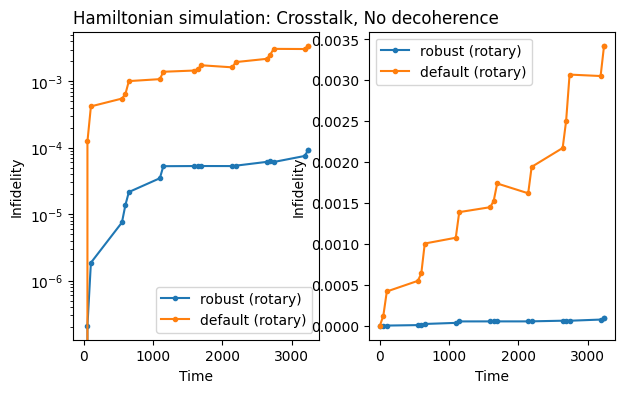

In [25]:
fig, axes = plt.subplots(1,2, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(2):
    ax = axes[iax]

    for i, res in enumerate(res_x0):
        infids = [0]
        if labels[i] == "default":
            continue
        for r, t in zip(res.y, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(np.hstack([0, *measure_times]), infids, label=labels[i], marker=".")

    # ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    # ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    # ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

### Plots for layers of Hamiltonian simulation

This is the crosstalk-free sim and plot. We won't need that sim for now.

This is the plot for the crosstalk example. We're still using that simulation up above.

 -4.80554277e-08 -4.61554656e-08 -4.05883380e-08 -3.80980966e-08
 -3.53468099e-08 -3.38523942e-08 -3.05187393e-08 -2.84206127e-08
 -2.52361185e-08 -2.18329050e-08 -2.01190893e-08 -1.49112874e-08]
 -1.01065216e-07 -9.46610251e-08 -9.20181152e-08 -8.54540509e-08
 -7.50812645e-08 -7.04462597e-08 -6.61287373e-08 -6.21464522e-08
 -5.43048567e-08 -5.12723224e-08 -4.82707636e-08 -4.16055717e-08]
 -1.46906579e-07 -1.41001031e-07 -1.36304977e-07 -1.27691427e-07
 -1.13932853e-07 -1.04206788e-07 -1.02116330e-07 -9.39028999e-08
 -8.20931646e-08 -7.98761455e-08 -7.26115430e-08 -6.25555847e-08]
 -1.99513996e-07 -1.89473290e-07 -1.82891444e-07 -1.71823014e-07
 -1.51571601e-07 -1.44150640e-07 -1.38418816e-07 -1.26606638e-07
 -1.10906526e-07 -1.07970587e-07 -9.92458608e-08 -8.76151088e-08]
 -2.42805866e-07 -2.37601177e-07 -2.24745555e-07 -2.15447343e-07
 -1.90827409e-07 -1.80857893e-07 -1.77636148e-07 -1.59593962e-07
 -1.41263918e-07 -1.38414765e-07 -1.24844225e-07 -1.12678045e-07]
 -2.90897947e-07 -2.

 -1.60525571e-06 -1.41969309e-06 -1.36420167e-06 -1.32494758e-06
 -1.26362774e-06 -1.25384979e-06 -1.22157657e-06 -1.19737577e-06
 -1.12893263e-06 -1.05836828e-06 -9.66178852e-07 -9.44612893e-07]
 -1.65286100e-06 -1.45959147e-06 -1.40733612e-06 -1.37008663e-06
 -1.29590807e-06 -1.29080508e-06 -1.25719252e-06 -1.23093049e-06
 -1.16421699e-06 -1.09421098e-06 -9.99390475e-07 -9.78502377e-07]
 -1.70107240e-06 -1.49979147e-06 -1.44969523e-06 -1.41422243e-06
 -1.33149418e-06 -1.32684272e-06 -1.29247604e-06 -1.26467636e-06
 -1.19873441e-06 -1.13010637e-06 -1.03380110e-06 -1.01209534e-06]
 -1.74932100e-06 -1.54017486e-06 -1.49112417e-06 -1.45716646e-06
 -1.36831163e-06 -1.36359576e-06 -1.32645036e-06 -1.29899215e-06
 -1.23399824e-06 -1.16580062e-06 -1.06753149e-06 -1.04657073e-06]
 -1.79805109e-06 -1.57973806e-06 -1.53278756e-06 -1.49808697e-06
 -1.40755248e-06 -1.40080791e-06 -1.36046492e-06 -1.33412690e-06
 -1.26805427e-06 -1.20164042e-06 -1.10245351e-06 -1.08041156e-06]
 -1.84681120e-06 -1.

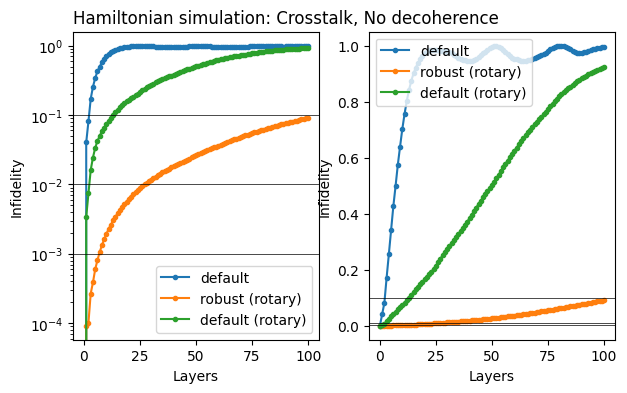

In [20]:
n = 100

fig, axes = plt.subplots(1, 2, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# fig.suptitle("Hamiltonian simulation: Crosstalk, No decoherence")
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')

# NOTE: Manually add a layer 0 for the initial state
layers = np.arange(0, n + 1)
Ulayers = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

for iax in range(len(axes)):
    ax = axes[iax]

    for i, res in enumerate(res_x0):
        # if labels[i] == "default":
        #     continue

        Ufs = itertools.accumulate(np.repeat([res.y[-1]], n, axis=0), np.matmul)
        infids = [0]
        for u, t in zip(Ufs, Ulayers):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(u), qk.quantum_info.Operator(t)))
        # Labels set previously
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

### With decoherence

In [30]:
qk.quantum_info.state_fidelity(y0.evolve(res_x0[0].y[-1]), y0.evolve(target))

0.9574251787912077

In [33]:
print("Case 3: Crosstalk and Decoherence")

# y0 = ps.qiskit_identity_operator(len(registers), open=True)
y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["default", "robust (rotary)", "default (rotary)"]
schedules = [sched, robust_sched, mix_sched]

solver_rx.model.evaluation_mode = "dense"
res_x = solver_rx.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))
y_target = y0.evolve(target)

# for i in range(len(res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(res_x[0].y[-1], target)}"
#     )

for i in range(len(res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(res_x[i].y[-1], y_target)}"
    )

Case 3: Crosstalk and Decoherence
	Infidelity of default schedule: 0.08179488824534653
	Infidelity of robust (rotary) schedule: 0.08179488824534653
	Infidelity of default (rotary) schedule: 0.08179488824534653


In [36]:
# Save the results
# format datetime for a file name
now = datetime.now()
dt_string = now.strftime("%Y-%m-%d-%H-%M-%S")
pkl.dump(
    {
        "res_x0": res_x0,
        "res_x": res_x,
        "measure_times": measure_times,
        "Uts": Uts,
    },
    open("../playground/{dt_string}-crosstalk-decoherence.pkl", "wb"),
)

 -1.00000000e+00 -1.00000000e+00 -1.00000000e+00 -1.00000000e+00
 -1.00000000e+00 -1.00000000e+00 -1.00000000e+00 -9.99999995e-01
 -9.99999995e-01 -9.99999995e-01 -9.99999995e-01 -5.87548194e-04]
 -1.         -1.         -1.         -1.         -1.         -0.99999994
 -0.99999994 -0.99999994 -0.99999994 -0.00195342]
 -1.         -1.         -1.         -1.         -0.99999987 -0.99999777
 -0.99999704 -0.99999697 -0.99999656 -0.01433316]
 -1.         -1.         -1.         -1.         -0.99999979 -0.99999754
 -0.99999669 -0.99999645 -0.99999586 -0.01552128]
 -1.         -1.         -1.         -1.         -0.99999971 -0.99999728
 -0.99999641 -0.9999958  -0.9999951  -0.01669887]
 -1.         -1.         -1.         -1.         -0.99999692 -0.99999629
 -0.99998852 -0.9999877  -0.99998562 -0.02876528]
 -1.         -1.         -1.         -1.         -0.99999673 -0.99999586
 -0.99998735 -0.99998655 -0.99998427 -0.03010259]
 -1.         -1.         -0.99999953 -0.99999939 -0.99999655 -0.99

ValueError: x and y must have same first dimension, but have shapes (18,) and (12,)

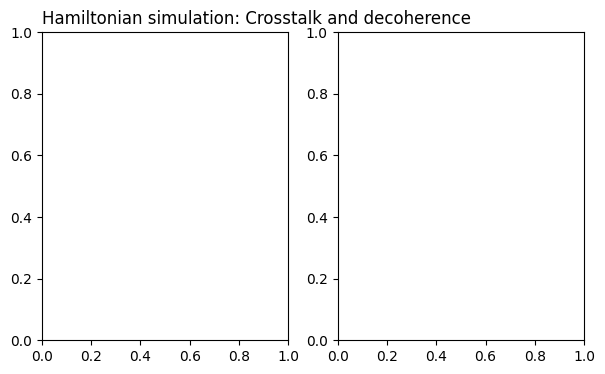

In [37]:
fig, axes = plt.subplots(1,2, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk and decoherence", loc='left')
labels = ["default", "robust (rotary)", "default (rotary)"]


# targets at measure times
Uts = []
for i, m in enumerate(my_moments):
    if ps.get_moment_case(m) == "single":
        Uts.append(ps.build_operator(my_moments[0:i+1], registers))
# and at the end time...
Uts.append(qk.quantum_info.Operator(ps.build_circuit(my_moments, registers)))
yts = [y0.evolve(Ut) for Ut in Uts]


for iax in range(len(axes)):
    ax = axes[iax]

    for i, res in enumerate(res_x):
        infids = []
        for y, t in zip(res.y, yts):
            
            infids.append(1 - qk.quantum_info.state_fidelity(y, t))
        ax.plot(measure_times, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

In [ ]:
n = 50

fig, axes = plt.subplots(1, 2, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# fig.suptitle("Hamiltonian simulation: Crosstalk and decoherence")
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')

layers = np.arange(1, n + 1)
Uts = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

for iax in range(len(axes)):
    ax = axes[iax]

    for i, r in enumerate(res_x):
        Ufs = itertools.accumulate(np.repeat([r.y[-1]], n, axis=0), np.matmul)
        infids = []
        for r, t in zip(Ufs, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(r, qk.quantum_info.Operator(t)))
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")